<a href="https://colab.research.google.com/github/Shibainulove/6070-001-202630/blob/main/Assignments/ASSIGNMENT%203%20-%20Visualizing%20a%20dataset./Xu_Assignment3_HousingPrices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — Visualizing a Dataset: Home Sale Prices in Neighborhood ABC

**Qingan Xu** · MSSP 607 · Case Study Report, Assignment 3

**Scenario.** As a real estate agent, I am advising clients who want to buy a home in neighborhood ABC. This notebook analyzes 1,460 recorded home sales (`HousingPrices.csv`, a 17-column subset of Kaggle's *House Prices — Advanced Regression Techniques* data) and produces every number and chart used in the written case study report.

| Required question | Answered in |
|---|---|
| 1. What are the mean and standard deviation of the price of housing? | Section 3 |
| 2. Generate a histogram of the housing price. | Section 4 |
| 3. Are there outliers that may affect the analysis? How should they be handled? | Section 5 |
| Beyond the questions: what drives price, a fair-value model, and buying advice | Sections 6–8 |

**Running in Google Colab:** choose *Runtime → Run all*. The setup cell clones this GitHub repository with the `Git_Key` secret from Colab Secrets, so `HousingPrices.csv` is already next to the notebook when the loading cell runs. Only libraries that ship with Colab are used (pandas, NumPy, SciPy, Matplotlib). Each chart is also saved as a PNG in a `figures/` folder.

*The assignment describes this as a fictitious data set used for learning, so the results are illustrative.*

## 1. Setup

In [ ]:
# Colab setup (Git_Key method). Opening this notebook from GitHub in Colab brings in only the
# .ipynb file, not the data files next to it. In Colab, this cell clones the repository with the
# GitHub token saved in Colab Secrets as Git_Key, then moves into this notebook's folder so the
# relative file paths below work as they do locally. Run locally, it changes nothing.
import os
import subprocess
from pathlib import Path

GITHUB_USER = "Shibainulove"
REPO = "6070-001-202630"
NOTEBOOK_DIR = "Assignments/ASSIGNMENT 3 - Visualizing a dataset."  # this notebook's folder in the repository

try:
    from google.colab import userdata
except ImportError:
    userdata = None  # not running in Colab

if userdata is None:
    print("Running locally: using the files next to this notebook")
else:
    repo_dir = Path("/content") / REPO
    if not repo_dir.exists():
        try:
            token = userdata.get("Git_Key")
        except Exception:  # no Git_Key secret, or this notebook was not given access to it
            token = ""  # cloning without a token still works while the repository is public
        login = f"{token}@" if token else ""
        url = f"https://{login}github.com/{GITHUB_USER}/{REPO}.git"
        clone = subprocess.run(["git", "clone", "--depth", "1", url, str(repo_dir)],
                               capture_output=True, text=True,
                               env={**os.environ, "GIT_TERMINAL_PROMPT": "0"})
        if clone.returncode != 0:
            details = clone.stderr.replace(token, "***") if token else clone.stderr
            raise RuntimeError("Could not clone the repository. In Colab Secrets (key icon), save a "
                               "GitHub token that can read it as Git_Key and turn on notebook access.\n"
                               + details)
        # Remove the token from the clone's saved remote address
        subprocess.run(["git", "-C", str(repo_dir), "remote", "set-url", "origin",
                        f"https://github.com/{GITHUB_USER}/{REPO}.git"], check=True)
    os.chdir(repo_dir / NOTEBOOK_DIR)
    print("Reading files from", Path.cwd())

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

# Colours: one accent hue for ordinary data, a second hue only to flag outliers or highlights,
# grey for context. The blue/orange pair stays distinguishable for colour-blind readers.
BLUE, ORANGE = "#2a78d6", "#eb6834"
LIGHT_BLUE, CONTEXT_GREY = "#9ec5f4", "#bfbdb6"
INK, INK_2, AXIS, GRIDLINE = "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10.5, "axes.labelsize": 10.5, "axes.labelcolor": INK_2,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRIDLINE, "grid.linewidth": 0.8,
    "legend.frameon": False, "legend.fontsize": 9.5,
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)


def save_fig(fig, name):
    """Save a chart as a 200-dpi PNG (these files are the figures in the written report)."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")


def usd(x, decimals=0):
    """Format a number as US dollars, e.g. usd(1234.5) -> '$1,235'."""
    sign = "-" if x < 0 else ""
    return f"{sign}${abs(x):,.{decimals}f}"


def k_fmt(x, pos=None):
    """Tick label in thousands of dollars, e.g. 150000 -> '$150K'."""
    return f"${x / 1000:,.0f}K"


def pct(v, decimals=0):
    """Signed percentage with a true minus sign, e.g. -0.18 -> '−18%'."""
    return f"{v:+.{decimals}%}".replace("-", "−")


def add_titles(ax, headline, subtitle=None, pad=10):
    """Left-aligned bold headline (the chart's takeaway) with an optional grey subtitle.

    Dollar signs are escaped so Matplotlib does not read "$...$" as a math formula.
    """
    ax.annotate(headline.replace("$", r"\$"), xy=(0, 1), xycoords="axes fraction",
                xytext=(0, pad + (18 if subtitle else 0)), textcoords="offset points",
                ha="left", va="bottom", fontsize=12.5, fontweight="bold", color=INK)
    if subtitle:
        ax.annotate(subtitle.replace("$", r"\$"), xy=(0, 1), xycoords="axes fraction", xytext=(0, pad),
                    textcoords="offset points", ha="left", va="bottom", fontsize=9.5, color=INK_2)

## 2. Load and inspect the data

In [2]:
DATA_FILE = "HousingPrices.csv"
DATA_URL = ""   # optional: the raw URL of the CSV if it sits in a public GitHub repository


def load_housing_data():
    """Read the CSV from this folder, from DATA_URL, or (in Colab) from an upload box."""
    if Path(DATA_FILE).exists():
        return pd.read_csv(DATA_FILE)
    if DATA_URL:
        return pd.read_csv(DATA_URL)
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Put HousingPrices.csv next to this notebook, or set DATA_URL.")
    print("HousingPrices.csv was not found in this Colab session - please select it below.")
    uploaded = files.upload()
    Path(DATA_FILE).write_bytes(next(iter(uploaded.values())))
    return pd.read_csv(DATA_FILE)


df = load_housing_data()
print(f"{df.shape[0]:,} homes x {df.shape[1]} columns")
df.head()

1,460 homes x 17 columns


,Id,LotFrontage,LotArea,HouseStyle,OverallQual,OverallCond,YearBuilt,TotalBsmtSF,CentralAir,1stFlrSF,2ndFlrSF,FullBath,TotalRooms,GarageCars,GarageArea,YrSold,SalePrice
0,1,65.0,8450.0,2Story,7,5,2003,856.0,Y,856,854,2,8,2,548,2008,208500
1,2,80.0,9600.0,1Story,6,8,1976,NaN,Y,1262,0,2,6,2,460,2007,181500
2,3,68.0,11250.0,2Story,7,5,2001,920.0,Y,920,866,2,6,2,608,2008,223500
3,4,60.0,9550.0,2Story,7,5,1915,NaN,Y,961,756,1,7,3,642,2006,140000
4,5,84.0,14260.0,2Story,8,5,2000,1145.0,Y,1145,1053,2,9,3,836,2008,250000


In [3]:
overview = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "non-missing": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing %": (df.isna().mean() * 100).round(1),
    "distinct values": df.nunique(),
})
display(overview)

print("Duplicate Ids:", df["Id"].duplicated().sum())
print("Duplicate rows (ignoring Id):", df.drop(columns="Id").duplicated().sum())
print("Homes with no missing value in any column:", df.notna().all(axis=1).sum())
print("Homes with no garage:", (df["GarageCars"] == 0).sum(),
      "| no second floor:", (df["2ndFlrSF"] == 0).sum(),
      "| basement area recorded as 0 sq ft:", (df["TotalBsmtSF"] == 0).sum())

,type,non-missing,missing,missing %,distinct values
Id,int64,1460,0,0.0,1460
LotFrontage,float64,1201,259,17.7,110
LotArea,float64,1341,119,8.2,993
HouseStyle,str,1460,0,0.0,8
OverallQual,int64,1460,0,0.0,10
OverallCond,int64,1460,0,0.0,9
YearBuilt,int64,1460,0,0.0,112
TotalBsmtSF,float64,913,547,37.5,541
CentralAir,str,1460,0,0.0,2
1stFlrSF,int64,1460,0,0.0,753


Duplicate Ids: 0
Duplicate rows (ignoring Id): 0
Homes with no missing value in any column: 694
Homes with no garage: 81 | no second floor: 829 | basement area recorded as 0 sq ft: 23


In [4]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.5,421.6,1.0,365.8,730.5,1095.2,1460.0
LotFrontage,1201.0,70.0,24.3,21.0,59.0,69.0,80.0,313.0
LotArea,1341.0,10440.1,10051.0,1300.0,7500.0,9382.0,11500.0,215245.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1460.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
TotalBsmtSF,913.0,1055.8,409.5,0.0,806.0,996.0,1286.0,3206.0
1stFlrSF,1460.0,1162.6,386.6,334.0,882.0,1087.0,1391.2,4692.0
2ndFlrSF,1460.0,347.0,436.5,0.0,0.0,0.0,728.0,2065.0
FullBath,1460.0,1.6,0.6,0.0,1.0,2.0,2.0,3.0


**What the inspection shows**

- 1,460 homes and 17 columns, one row per sale, with no duplicate records. `SalePrice` has no missing values, so the three required questions use every sale.
- Three columns have gaps: basement area `TotalBsmtSF` (547 missing, 37.5%), `LotFrontage` (259, 17.7%) and `LotArea` (119, 8.2%). Only 694 homes (47.5%) have all three, so dropping incomplete rows would discard more than half of the data. Section 5.6 deals with this.
- Zeros are real values, not missing ones: 81 homes have no garage, 829 have no second floor, and 23 recorded basements measure 0 sq ft (no basement).
- `TotalRooms` counts rooms above ground excluding bathrooms (Kaggle's `TotRmsAbvGrd`); `OverallQual` and `OverallCond` are 1–10 ratings of the home's materials and finish and of its condition.

I add four working columns: above-ground living area (`LivArea` = first floor + second floor), price per square foot, the natural log of price, and a 0/1 flag for central air.

In [5]:
df["LivArea"] = df["1stFlrSF"] + df["2ndFlrSF"]        # above-ground living area, sq ft
df["PricePerSqFt"] = df["SalePrice"] / df["LivArea"]
df["LogPrice"] = np.log(df["SalePrice"])
df["CentralAirY"] = (df["CentralAir"] == "Y").astype(int)
df[["SalePrice", "LivArea", "PricePerSqFt", "LogPrice", "CentralAirY"]].describe().round(2)

,SalePrice,LivArea,PricePerSqFt,LogPrice,CentralAirY
count,1460.0,1460.00,1460.00,1460.00,1460.00
mean,180921.2,1509.62,120.94,12.02,0.93
std,79442.5,521.16,31.19,0.40,0.25
min,34900.0,334.00,28.36,10.46,0.00
25%,129975.0,1123.75,100.40,11.78,1.00
50%,163000.0,1458.00,120.34,12.00,1.00
75%,214000.0,1775.25,138.92,12.27,1.00
max,755000.0,5642.00,276.25,13.53,1.00


## 3. Question 1 — Mean and standard deviation of the price of housing

In [6]:
price = df["SalePrice"]
mean_price = price.mean()
sd_price = price.std()              # sample standard deviation (divides by n - 1)
sd_price_pop = price.std(ddof=0)    # population standard deviation (divides by n)
q1, median_price, q3 = price.quantile([0.25, 0.50, 0.75])

print(f"Mean sale price:                 {usd(mean_price, 2)}")
print(f"Standard deviation (sample):     {usd(sd_price, 2)}")
print(f"Standard deviation (population): {usd(sd_price_pop, 2)}")

within_1sd = price.between(mean_price - sd_price, mean_price + sd_price).mean()
summary = pd.DataFrame({"SalePrice": {
    "Homes": f"{price.count():,}",
    "Mean": usd(mean_price, 2),
    "Standard deviation (sample)": usd(sd_price, 2),
    "Coefficient of variation (SD / mean)": f"{sd_price / mean_price:.1%}",
    "Minimum": usd(price.min()),
    "25th percentile (Q1)": usd(q1),
    "Median": usd(median_price),
    "75th percentile (Q3)": usd(q3),
    "Maximum": usd(price.max()),
    "Share of homes within 1 SD of the mean": f"{within_1sd:.1%}",
    "Skewness": f"{price.skew():.2f}",
    "Excess kurtosis": f"{price.kurt():.2f}",
}})
display(summary)

Mean sale price:                 $180,921.20
Standard deviation (sample):     $79,442.50
Standard deviation (population): $79,415.29


,SalePrice
Homes,"1,460"
Mean,"$180,921.20"
Standard deviation (sample),"$79,442.50"
Coefficient of variation (SD / mean),43.9%
Minimum,"$34,900"
25th percentile (Q1),"$129,975"
Median,"$163,000"
75th percentile (Q3),"$214,000"
Maximum,"$755,000"
Share of homes within 1 SD of the mean,78.4%


**Answer to Q1.** The mean sale price is **\$180,921.20** and the standard deviation is **\$79,442.50** (sample standard deviation, dividing by n − 1; the population version is \$79,415.29).

How to read it: the standard deviation is 44% of the mean, so prices vary widely. The mean sits about \$18,000 above the median (\$163,000) because a tail of expensive homes pulls it upward (skewness 1.88), and 78% of homes fall within one standard deviation of the mean rather than the 68% a bell curve would give. For a buyer, the median and the middle half of the market (\$129,975–\$214,000) describe a typical home better than the mean does.

## 4. Question 2 — Histogram of the housing price

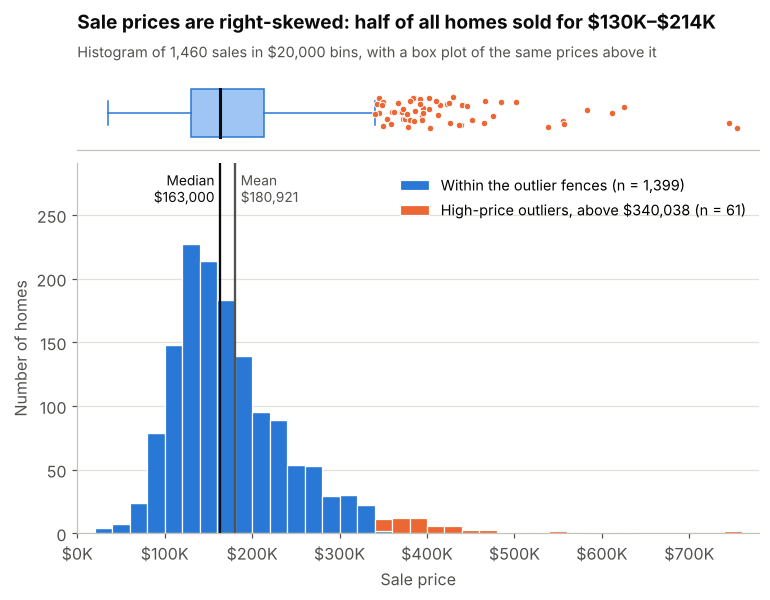

In [7]:
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr     # Tukey's fences (used again in Q3)
is_high = price > upper_fence
inside = price[price.between(lower_fence, upper_fence)]
low_whisker, high_whisker = inside.min(), inside.max()

fig, (ax_box, ax) = plt.subplots(2, 1, sharex=True, figsize=(8, 5.4),
                                 gridspec_kw={"height_ratios": [1, 5], "hspace": 0.06})

# Box-plot strip, drawn by hand so it looks the same in every Matplotlib version:
# box = middle 50%, dark line = median, whiskers reach the most extreme prices inside the fences.
ax_box.add_patch(plt.Rectangle((q1, -0.32), q3 - q1, 0.64, facecolor=LIGHT_BLUE, edgecolor=BLUE, linewidth=1))
ax_box.plot([median_price, median_price], [-0.32, 0.32], color=INK, linewidth=2)
for start, end in [(low_whisker, q1), (q3, high_whisker)]:
    ax_box.plot([start, end], [0, 0], color=BLUE, linewidth=1)
for cap in (low_whisker, high_whisker):
    ax_box.plot([cap, cap], [-0.16, 0.16], color=BLUE, linewidth=1)
jitter = np.random.default_rng(1).uniform(-0.22, 0.22, is_high.sum())
ax_box.scatter(price[is_high], jitter, s=18, color=ORANGE, edgecolors="white", linewidths=0.6, zorder=3)
ax_box.set_ylim(-0.5, 0.5)
ax_box.set_yticks([])
ax_box.grid(False)
ax_box.spines["left"].set_visible(False)
ax_box.tick_params(axis="x", length=0)

# Histogram in $20,000 bins; bars of high-price outliers are stacked in orange.
bins = np.arange(20_000, 780_001, 20_000)
counts, _, _ = ax.hist([price[~is_high].to_numpy(), price[is_high].to_numpy()], bins=bins, stacked=True,
                       color=[BLUE, ORANGE], edgecolor="white", linewidth=0.8,
                       label=[f"Within the outlier fences (n = {(~is_high).sum():,})",
                              f"High-price outliers, above {usd(upper_fence)} (n = {is_high.sum()})"])
tallest = counts[-1].max()                 # stacked: the last layer holds the bar totals
ax.set_ylim(0, tallest * 1.28)
ax.axvline(median_price, color=INK, linewidth=1.5)
ax.axvline(mean_price, color=INK_2, linewidth=1.5)
ax.text(median_price - 6_000, tallest * 1.25, f"Median\n{usd(median_price)}", ha="right", va="top", fontsize=9, color=INK)
ax.text(mean_price + 6_000, tallest * 1.25, f"Mean\n{usd(mean_price)}", ha="left", va="top", fontsize=9, color=INK_2)
ax.set_xlim(0, 780_000)
ax.set_xticks(np.arange(0, 700_001, 100_000))
ax.xaxis.set_major_formatter(FuncFormatter(k_fmt))
ax.set_xlabel("Sale price")
ax.set_ylabel("Number of homes")
ax.legend(loc="upper right")
add_titles(ax_box, f"Sale prices are right-skewed: half of all homes sold for {k_fmt(q1)}–{k_fmt(q3)}",
           f"Histogram of {len(price):,} sales in $20,000 bins, with a box plot of the same prices above it")
save_fig(fig, "price_histogram")
plt.show()

**Reading the histogram.** Sales pile up between about \$100,000 and \$250,000 (77% of homes), with the tallest bars at \$120,000–\$160,000. The right tail stretches to \$755,000 while the cheapest home sold for \$34,900, so the distribution is right-skewed rather than bell-shaped. The box-plot strip shows the same thing: the box (middle 50%) spans \$129,975–\$214,000, and 61 sales (orange) lie beyond the upper whisker.

Home prices tend to differ in percentage steps rather than fixed dollar amounts, so on a log scale the distribution becomes nearly symmetric (below). That is why the value model in Section 7 works with log price.

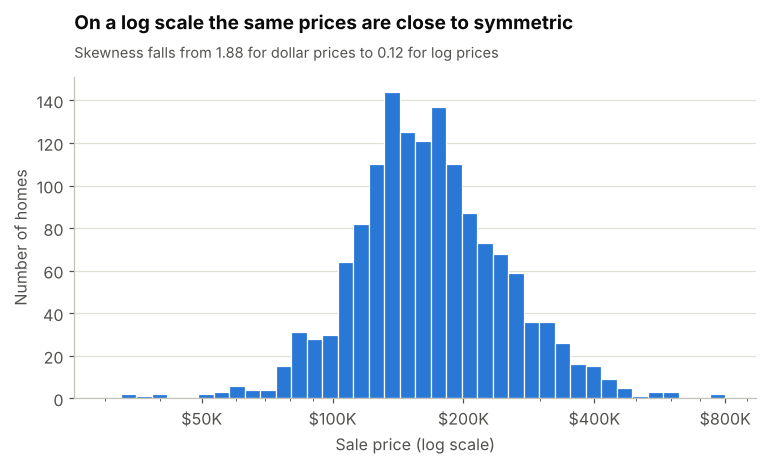

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(price, bins=np.geomspace(30_000, 800_000, 41), color=BLUE, edgecolor="white", linewidth=0.8)
ax.set_xscale("log")
ax.set_xticks([50_000, 100_000, 200_000, 400_000, 800_000])
ax.xaxis.set_major_formatter(FuncFormatter(k_fmt))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("Sale price (log scale)")
ax.set_ylabel("Number of homes")
add_titles(ax, "On a log scale the same prices are close to symmetric",
           f"Skewness falls from {price.skew():.2f} for dollar prices to {df['LogPrice'].skew():.2f} for log prices")
save_fig(fig, "log_price_histogram")
plt.show()

## 5. Question 3 — Outliers that may affect the analysis

Two kinds of outliers matter here:

1. **Price outliers** — homes whose price alone is extreme. These pull the mean and standard deviation around.
2. **Influential sales** — homes whose price is out of line with what they are. Their price may look ordinary, but they distort relationships such as "how much is an extra square foot worth".

### 5.1 Price outliers: Tukey's fences

A price counts as an outlier when it lies more than 1.5 × IQR (interquartile range) beyond the quartiles — the box-plot rule. For comparison, the table also applies a stricter 3 × IQR rule, the z-score rule (more than 3 standard deviations from the mean), and the 1.5 × IQR rule on log prices.

In [9]:
z = (price - mean_price) / sd_price
log_q1, log_q3 = df["LogPrice"].quantile([0.25, 0.75])
log_iqr = log_q3 - log_q1

rule_rows = []
for rule, values, low, high, to_dollars in [
    ("1.5 x IQR (Tukey's fences, main rule)", price, lower_fence, upper_fence, lambda v: v),
    ("3 x IQR ('extreme' outliers)", price, q1 - 3 * iqr, q3 + 3 * iqr, lambda v: v),
    ("|z-score| > 3", z, -3, 3, lambda v: mean_price + v * sd_price),
    ("1.5 x IQR on log price", df["LogPrice"], log_q1 - 1.5 * log_iqr, log_q3 + 1.5 * log_iqr, np.exp),
]:
    rule_rows.append({"Rule": rule,
                      "Low cut-off": usd(to_dollars(low)), "High cut-off": usd(to_dollars(high)),
                      "Low outliers": int((values < low).sum()), "High outliers": int((values > high).sum())})
display(pd.DataFrame(rule_rows))
print(f"IQR = {usd(iqr)}. Main rule: {is_high.sum()} high outliers ({is_high.mean():.1%} of homes), "
      f"{(price < lower_fence).sum()} low outliers.")

,Rule,Low cut-off,High cut-off,Low outliers,High outliers
0,"1.5 x IQR (Tukey's fences, main rule)","$3,938","$340,038",0,61
1,3 x IQR ('extreme' outliers),"-$122,100","$466,075",0,12
2,|z-score| > 3,"-$57,406","$419,249",0,22
3,1.5 x IQR on log price,"$61,522","$452,111",15,13


IQR = $84,025. Main rule: 61 high outliers (4.2% of homes), 0 low outliers.


The main rule flags **61 homes priced above \$340,037.50 (4.2% of sales) and none on the low side** — the lower fence (\$3,937.50) sits far below the cheapest sale. The z-score rule flags fewer (22) because it is built on the mean and standard deviation, which the outliers themselves inflate; the IQR rule is the safer choice for skewed data. On the log scale the picture is more balanced: 13 expensive and 15 very cheap homes stand out.

### 5.2 Who are the high-price outliers?

In [10]:
profile_cols = {"SalePrice": "Median sale price ($)", "OverallQual": "Median overall quality (1-10)",
                "LivArea": "Median living area (sq ft)", "YearBuilt": "Median year built",
                "GarageCars": "Median garage capacity (cars)", "PricePerSqFt": "Median price per sq ft ($)"}
profile = pd.DataFrame({
    f"High-price outliers (n = {is_high.sum()})": df.loc[is_high, list(profile_cols)].median(),
    f"All other homes (n = {(~is_high).sum():,})": df.loc[~is_high, list(profile_cols)].median(),
}).rename(index=profile_cols).round(0).astype(int)
display(profile)
print("Quality ratings of the outliers:", df.loc[is_high, "OverallQual"].value_counts().sort_index().to_dict())
print(f"Central air: {df.loc[is_high, 'CentralAirY'].mean():.0%} of outliers vs "
      f"{df.loc[~is_high, 'CentralAirY'].mean():.0%} of other homes")

,High-price outliers (n = 61),"All other homes (n = 1,399)"
Median sale price ($),394617,159500
Median overall quality (1-10),9,6
Median living area (sq ft),2364,1434
Median year built,2006,1971
Median garage capacity (cars),3,2
Median price per sq ft ($),182,119


Quality ratings of the outliers: {7: 3, 8: 22, 9: 23, 10: 13}
Central air: 100% of outliers vs 93% of other homes


These are not data errors. They are the neighborhood's best-built, largest and newest homes: every one is rated 7 or higher for quality (most 8–9), the typical one was built in 2006 with a three-car garage, and they sell for a median \$182 per square foot versus \$119 for the rest. Deleting them would misdescribe the ABC market, so they stay in the data.

### 5.3 How much do they move the mean and standard deviation?

In [11]:
def describe_prices(s):
    return pd.Series({"Homes": len(s), "Mean": s.mean(), "Standard deviation": s.std(),
                      "Median": s.median(), "Interquartile range": s.quantile(0.75) - s.quantile(0.25),
                      "Skewness": s.skew()})


impact = pd.DataFrame({"All homes": describe_prices(price),
                       f"Without the {is_high.sum()} high-price outliers": describe_prices(price[~is_high])})
impact["Change"] = impact.iloc[:, 1] - impact.iloc[:, 0]
impact["Change (%)"] = impact["Change"] / impact.iloc[:, 0] * 100
display(impact.round(2))

,All homes,Without the 61 high-price outliers,Change,Change (%)
Homes,1460.00,1399.00,-61.00,-4.18
Mean,180921.20,170237.13,-10684.07,-5.91
Standard deviation,79442.50,59230.13,-20212.37,-25.44
Median,163000.00,159500.00,-3500.00,-2.15
Interquartile range,84025.00,74500.00,-9525.00,-11.34
Skewness,1.88,0.68,-1.20,-63.90


Dropping the 61 homes would lower the mean by about \$10,700 (−5.9%) and the standard deviation by about \$20,200 (−25%), but the median by only \$3,500. The Q1 answer therefore leans heavily on a small tail of luxury sales, while the median and IQR barely move. This is why the report gives the median and IQR next to the mean and standard deviation.

### 5.4 Sales that don't fit the pattern: two oversized homes

De Cock, who compiled the original data, notes that the few homes over 4,000 sq ft include partial sales that likely do not reflect market value, and he recommends removing houses over 4,000 sq ft. Four homes in this subset are that large:

In [12]:
big = df.loc[df["LivArea"] > 4000, ["Id", "SalePrice", "LivArea", "PricePerSqFt", "OverallQual", "YearBuilt", "YrSold"]]
display(big.sort_values("PricePerSqFt").round(1))

q10_ppsf = df.loc[df["OverallQual"] == 10, "PricePerSqFt"].median()
anomaly = (df["LivArea"] > 4000) & (df["PricePerSqFt"] < 0.5 * q10_ppsf)
anomaly_ids = df.loc[anomaly, "Id"].tolist()
print(f"Median price per sq ft of quality-10 homes: {usd(q10_ppsf, 2)}")
print(f"Anomalous sales (over 4,000 sq ft but priced at less than half that rate): Ids {anomaly_ids}")

,Id,SalePrice,LivArea,PricePerSqFt,OverallQual,YearBuilt,YrSold
1298,1299,160000,5642,28.4,10,2008,2008
523,524,184750,4676,39.5,10,2007,2007
1182,1183,745000,4476,166.4,10,1996,2007
691,692,755000,4316,174.9,10,1994,2007


Median price per sq ft of quality-10 homes: $173.62
Anomalous sales (over 4,000 sq ft but priced at less than half that rate): Ids [524, 1299]


All sales:              +$109.28 per sq ft, r = 0.717
Without the anomalies:  +$117.51 per sq ft, r = 0.744
Change in slope: +$8.24 per sq ft (+7.5%)


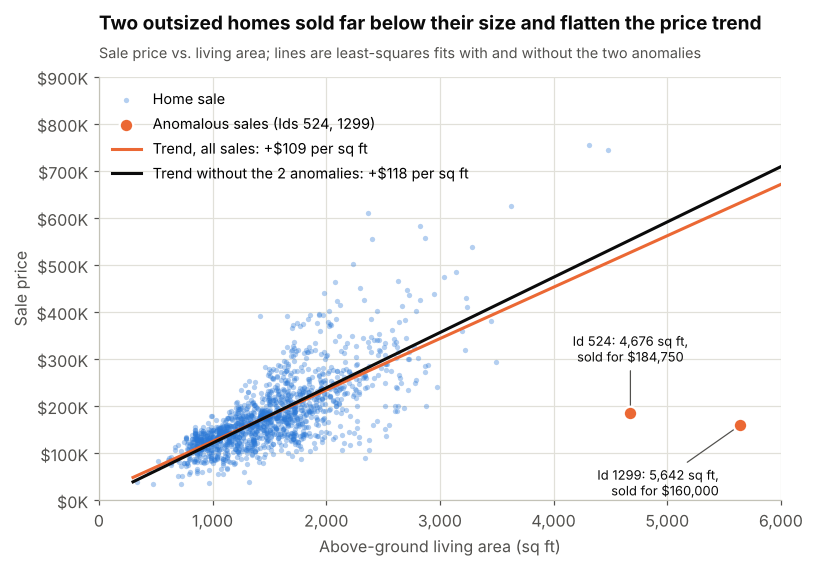

In [13]:
fit_all = stats.linregress(df["LivArea"], df["SalePrice"])
fit_clean = stats.linregress(df.loc[~anomaly, "LivArea"], df.loc[~anomaly, "SalePrice"])
print(f"All sales:              +{usd(fit_all.slope, 2)} per sq ft, r = {fit_all.rvalue:.3f}")
print(f"Without the anomalies:  +{usd(fit_clean.slope, 2)} per sq ft, r = {fit_clean.rvalue:.3f}")
print(f"Change in slope: +{usd(fit_clean.slope - fit_all.slope, 2)} per sq ft "
      f"({fit_clean.slope / fit_all.slope - 1:+.1%})")

fig, ax = plt.subplots(figsize=(8, 5))
ax.grid(True, axis="both")
ax.scatter(df.loc[~anomaly, "LivArea"], df.loc[~anomaly, "SalePrice"], s=12, color=BLUE, alpha=0.35,
           linewidths=0, label="Home sale")
ax.scatter(df.loc[anomaly, "LivArea"], df.loc[anomaly, "SalePrice"], s=80, color=ORANGE, edgecolors="white",
           linewidths=1.5, zorder=4, label=f"Anomalous sales (Ids {', '.join(map(str, anomaly_ids))})")
x_line = np.array([300, 6000])
ax.plot(x_line, fit_all.intercept + fit_all.slope * x_line, color=ORANGE, linewidth=2,
        label=f"Trend, all sales: +${fit_all.slope:,.0f} per sq ft")
ax.plot(x_line, fit_clean.intercept + fit_clean.slope * x_line, color=INK, linewidth=2,
        label=f"Trend without the 2 anomalies: +${fit_clean.slope:,.0f} per sq ft")
placements = [((0, 34), "center"), ((-14, -46), "right")]       # label above the first, below-left of the second
for (_, row), (offset, align) in zip(df.loc[anomaly].sort_values("LivArea").iterrows(), placements):
    ax.annotate(f"Id {int(row['Id'])}: {row['LivArea']:,.0f} sq ft,\nsold for {usd(row['SalePrice'])}",
                xy=(row["LivArea"], row["SalePrice"]), xytext=offset, textcoords="offset points",
                ha=align, fontsize=8.5, color=INK, arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.8))
ax.set_xlim(0, 6000)
ax.set_ylim(0, 900_000)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(k_fmt))
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price")
ax.legend(loc="upper left")
add_titles(ax, "Two outsized homes sold far below their size and flatten the price trend",
           "Sale price vs. living area; lines are least-squares fits with and without the two anomalies")
save_fig(fig, "size_outliers")
plt.show()

Ids 524 and 1299 are brand-new (each sold in the year it was built, 2007 and 2008), top-quality homes of 4,676 and 5,642 sq ft that sold for \$184,750 and \$160,000 — \$40 and \$28 per square foot, against a median of \$174 for quality-10 homes. Their prices are unremarkable on their own, so the IQR rule misses them, but they sit at the far right of the size axis and pull the fitted line down. With them, an extra square foot appears to be worth \$109; without them, \$118. The other two large homes (Ids 692 and 1183, the two most expensive sales at \$755,000 and \$745,000) sell at quality-10 rates and follow the trend, so I keep them.

### 5.5 Confirming their influence with Cook's distance

Cook's distance measures how much the fitted model would change if a single observation were removed. I compute it for the fair-value model used in Section 7 (log price explained by quality grade, living area, garage capacity, year built, condition and central air), fitted to all 1,460 sales. The model is estimated with a short NumPy least-squares helper so the notebook needs no extra packages.

In [14]:
# Quality grades 1-3 are rare (25 homes), so they are pooled; grade 6 is the reference category.
df["QualGroup"] = df["OverallQual"].clip(lower=3)
QUAL_DUMMIES = {"Qual_1to3": 3, "Qual_4": 4, "Qual_5": 5, "Qual_7": 7, "Qual_8": 8, "Qual_9": 9, "Qual_10": 10}
for col, grade in QUAL_DUMMIES.items():
    df[col] = (df["QualGroup"] == grade).astype(int)
df["LogLivArea"] = np.log(df["LivArea"])
PREDICTORS = list(QUAL_DUMMIES) + ["LogLivArea", "GarageCars", "YearBuilt", "OverallCond", "CentralAirY"]


def fit_ols(data, y, predictors):
    """Ordinary least squares with an intercept, written with NumPy.

    Returns the coefficient table, fit statistics, fitted values, residuals and Cook's distance.
    """
    d = data.dropna(subset=[y] + predictors)
    X = np.column_stack([np.ones(len(d))] + [d[p].to_numpy(dtype=float) for p in predictors])
    Y = d[y].to_numpy(dtype=float)
    beta = np.linalg.lstsq(X, Y, rcond=None)[0]
    fitted = X @ beta
    resid = Y - fitted
    n, k = X.shape
    s2 = resid @ resid / (n - k)                              # residual variance
    XtX_inv = np.linalg.inv(X.T @ X)
    se = np.sqrt(np.diag(s2 * XtX_inv))
    t_stat = beta / se
    p_val = 2 * stats.t.sf(np.abs(t_stat), df=n - k)
    r2 = 1 - (resid @ resid) / ((Y - Y.mean()) @ (Y - Y.mean()))
    leverage = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
    cooks_d = resid ** 2 / (k * s2) * leverage / (1 - leverage) ** 2
    return {
        "predictors": predictors,
        "coefs": pd.DataFrame({"coef": beta, "std_err": se, "t": t_stat, "p_value": p_val},
                              index=["Intercept"] + predictors),
        "n": n, "r2": r2, "adj_r2": 1 - (1 - r2) * (n - 1) / (n - k), "resid_sd": np.sqrt(s2),
        "fitted": pd.Series(fitted, index=d.index), "resid": pd.Series(resid, index=d.index),
        "cooks_d": pd.Series(cooks_d, index=d.index),
    }


def predict_log_price(model, data):
    """Predicted log price for any rows that have the model's predictors."""
    X = np.column_stack([np.ones(len(data))] + [data[p].to_numpy(dtype=float) for p in model["predictors"]])
    return pd.Series(X @ model["coefs"]["coef"].to_numpy(), index=data.index)

In [15]:
model_all = fit_ols(df, "LogPrice", PREDICTORS)
cooks = model_all["cooks_d"].sort_values(ascending=False)
top_influence = df.loc[cooks.index[:6], ["Id", "SalePrice", "LivArea", "OverallQual", "YearBuilt"]].copy()
top_influence["Cook's distance"] = cooks.iloc[:6].round(3)
display(top_influence)

anomaly_cooks = dict(zip(df.loc[anomaly, "Id"], cooks[df.index[anomaly]].round(3)))
print("Cook's distance of the two anomalies:", anomaly_cooks,
      "| largest among all other homes:", round(cooks.drop(index=df.index[anomaly]).max(), 3))

,Id,SalePrice,LivArea,OverallQual,YearBuilt,Cook's distance
1298,1299,160000,5642,10,2008,0.351
523,524,184750,4676,10,2007,0.235
968,969,37900,968,3,1910,0.057
30,31,40000,1317,4,1920,0.036
1182,1183,745000,4476,10,1996,0.028
691,692,755000,4316,10,1994,0.025


Cook's distance of the two anomalies: {524: 0.235, 1299: 0.351} | largest among all other homes: 0.057


The two anomalies have by far the largest Cook's distances (0.35 and 0.24, against 0.06 for the next home), confirming that these two sales, more than any others, bend the model.

### 5.6 Missing values

Missing data can bias results if the homes with gaps differ from the rest. A Mann–Whitney test compares the prices of homes with and without each value recorded.

In [16]:
rows = []
for col in ["TotalBsmtSF", "LotFrontage", "LotArea"]:
    miss = df[col].isna()
    test = stats.mannwhitneyu(df.loc[miss, "SalePrice"], df.loc[~miss, "SalePrice"])
    rows.append({"Column": col, "Missing": int(miss.sum()), "Share missing": f"{miss.mean():.1%}",
                 "Median price, value missing": usd(df.loc[miss, "SalePrice"].median()),
                 "Median price, value recorded": usd(df.loc[~miss, "SalePrice"].median()),
                 "Mann-Whitney p-value": round(test.pvalue, 3)})
display(pd.DataFrame(rows).set_index("Column"))
complete = df[["TotalBsmtSF", "LotFrontage", "LotArea"]].notna().all(axis=1)
print(f"Homes with all three recorded: {complete.sum():,} of {len(df):,} ({complete.mean():.1%})")

,Missing,Share missing,"Median price, value missing","Median price, value recorded",Mann-Whitney p-value
Column,,,,,
TotalBsmtSF,547,37.5%,"$165,500","$161,500",0.169
LotFrontage,259,17.7%,"$172,400","$159,500",0.009
LotArea,119,8.2%,"$175,500","$161,500",0.101


Homes with all three recorded: 694 of 1,460 (47.5%)


Basement and lot area are missing in a way that is unrelated to price (p > 0.10), but homes missing `LotFrontage` sell for more (p = 0.009), so those gaps are not random: filling them with an average would bias the data. None of the three columns is needed for Q1–Q3, and dropping incomplete homes would discard 52% of the sample. I therefore leave these columns out of the main model and check on the complete cases that adding them does not change the conclusions (Section 7.4).

### 5.7 How I handle the outliers (answer to Q3)

**Yes — outliers matter here, and the two kinds call for different treatment:**

1. **61 high-price outliers (above \$340,037.50).** Genuine luxury sales, not errors, so I keep them. Because they inflate the mean by about \$10,700 and the standard deviation by about \$20,200, I (a) report the median and interquartile range alongside the mean and standard deviation, (b) model log price, which tames the long right tail, and (c) treat homes rated 8–10 for quality as a separate market segment in the recommendations.
2. **Two anomalous sales (Ids 524 and 1299).** Their prices are not plausible market values for brand-new 4,700–5,600 sq ft homes, consistent with the partial sales De Cock describes, and they distort every size-related estimate. I keep them in the descriptive statistics for Q1 and Q2 (they are recorded sales) but exclude them from the fair-value model.
3. **Missing values.** Instead of deleting half the homes, the main model uses only fully recorded columns; Section 7.4 checks the result against the incomplete columns.

## 6. What drives sale price?

,Pearson r,Spearman rho
OverallQual,0.791,0.810
LivArea,0.717,0.738
GarageCars,0.640,0.691
YearBuilt,0.523,0.653
GarageArea,0.623,0.649
FullBath,0.561,0.636
TotalBsmtSF,0.642,0.609
1stFlrSF,0.606,0.575
TotalRooms,0.534,0.533
LotArea,0.268,0.461


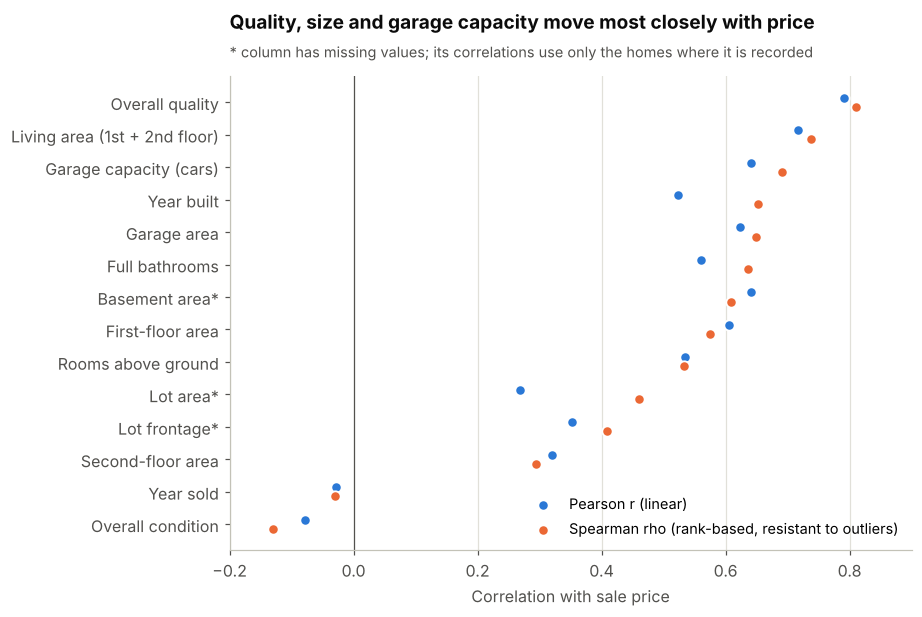

Overlapping measures: GarageCars vs GarageArea r = 0.88 | LivArea vs TotalRooms r = 0.82


In [17]:
labels = {
    "OverallQual": "Overall quality", "LivArea": "Living area (1st + 2nd floor)", "GarageCars": "Garage capacity (cars)",
    "GarageArea": "Garage area", "TotalBsmtSF": "Basement area*", "1stFlrSF": "First-floor area",
    "FullBath": "Full bathrooms", "TotalRooms": "Rooms above ground", "YearBuilt": "Year built",
    "LotFrontage": "Lot frontage*", "2ndFlrSF": "Second-floor area", "LotArea": "Lot area*",
    "OverallCond": "Overall condition", "YrSold": "Year sold",
}
corr = pd.DataFrame({
    "Pearson r": df[list(labels)].corrwith(df["SalePrice"]),
    "Spearman rho": df[list(labels)].corrwith(df["SalePrice"], method="spearman"),
}).sort_values("Spearman rho")
display(corr.sort_values("Spearman rho", ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 5.6))
ax.grid(False)
ax.grid(True, axis="x")
y = np.arange(len(corr))
# The two measures are drawn slightly apart so neither hides the other when they are equal.
ax.scatter(corr["Pearson r"], y + 0.14, s=46, color=BLUE, edgecolors="white", linewidths=1.2, zorder=3,
           label="Pearson r (linear)")
ax.scatter(corr["Spearman rho"], y - 0.14, s=46, color=ORANGE, edgecolors="white", linewidths=1.2, zorder=3,
           label="Spearman rho (rank-based, resistant to outliers)")
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels([labels[c] for c in corr.index])
ax.set_xlim(-0.2, 0.9)
ax.set_xlabel("Correlation with sale price")
ax.legend(loc="lower right")
add_titles(ax, "Quality, size and garage capacity move most closely with price",
           "* column has missing values; its correlations use only the homes where it is recorded")
save_fig(fig, "correlations")
plt.show()
print("Overlapping measures: GarageCars vs GarageArea r =", round(df["GarageCars"].corr(df["GarageArea"]), 2),
      "| LivArea vs TotalRooms r =", round(df["LivArea"].corr(df["TotalRooms"]), 2))

**Overall quality** is the single strongest correlate of price (r = 0.79), followed by **living area** (0.72) and **garage capacity** (0.64). Year built correlates more strongly by rank (0.65) than linearly (0.52) because newer homes command a growing premium. Two results look surprising at first. **Condition** is slightly *negatively* related to price, because most new homes carry an "average" condition rating of 5 while older homes are rated anywhere from 1 to 9; once age is held constant (Section 7), better condition adds value. **Year sold** has almost no relationship with price, so prices held steady from 2006 to 2010. Garage area duplicates garage capacity (r = 0.88) and room count duplicates living area (r = 0.82), so the model uses one of each.

In [18]:
by_quality = df.groupby("OverallQual").agg(
    homes=("SalePrice", "size"),
    median_price=("SalePrice", "median"),
    median_living_area=("LivArea", "median"),
    median_price_per_sqft=("PricePerSqFt", "median"),
    pct_central_air=("CentralAirY", "mean"),
)
by_quality["median_price_per_sqft"] = by_quality["median_price_per_sqft"].round(1)
by_quality["pct_central_air"] = (by_quality["pct_central_air"] * 100).round(0)
display(by_quality)

,homes,median_price,median_living_area,median_price_per_sqft,pct_central_air
OverallQual,,,,,
1,2,50150.0,619.0,92.6,0.0
2,3,60000.0,480.0,75.0,0.0
3,20,86250.0,1040.0,84.3,45.0
4,116,108000.0,1043.5,101.9,80.0
5,397,133000.0,1142.0,117.3,92.0
6,374,160000.0,1435.5,114.6,95.0
7,319,200141.0,1656.0,125.6,98.0
8,168,269750.0,1813.5,143.2,99.0
9,43,345000.0,1922.0,176.2,100.0


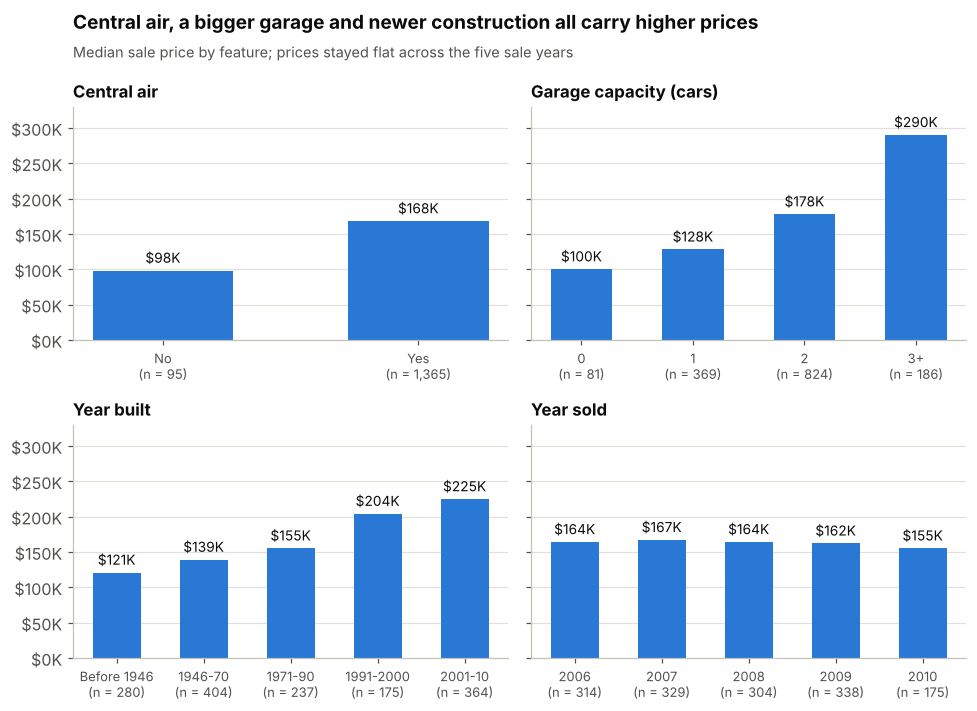

In [19]:
def median_by(groups):
    g = df.groupby(groups, observed=True)["SalePrice"]
    return g.median(), g.size()


garage = df["GarageCars"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
era = pd.cut(df["YearBuilt"], bins=[0, 1945, 1970, 1990, 2000, 2010],
             labels=["Before 1946", "1946-70", "1971-90", "1991-2000", "2001-10"])
panels = [("Central air", df["CentralAir"].map({"N": "No", "Y": "Yes"})),
          ("Garage capacity (cars)", garage),
          ("Year built", era),
          ("Year sold", df["YrSold"].astype(str))]

fig, axes = plt.subplots(2, 2, figsize=(9, 6.6), sharey=True)
for ax, (title, groups) in zip(axes.flat, panels):
    med, n = median_by(groups)
    x = np.arange(len(med))
    bars = ax.bar(x, med.to_numpy(), width=0.55, color=BLUE)
    ax.bar_label(bars, labels=[k_fmt(v) for v in med], padding=3, fontsize=9, color=INK)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{name}\n(n = {count:,})" for name, count in zip(med.index, n)], fontsize=8.5)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold", color=INK)
    ax.yaxis.set_major_formatter(FuncFormatter(k_fmt))
axes[0, 0].set_ylim(0, 330_000)
fig.tight_layout(rect=(0, 0, 1, 0.9))
add_titles(axes[0, 0], "Central air, a bigger garage and newer construction all carry higher prices",
           "Median sale price by feature; prices stayed flat across the five sale years", pad=30)
save_fig(fig, "price_patterns")
plt.show()

In [20]:
by_era = df.groupby(era, observed=True).agg(
    homes=("SalePrice", "size"),
    median_price=("SalePrice", "median"),
    median_price_per_sqft=("PricePerSqFt", "median"),
    median_condition=("OverallCond", "median"),
)
display(by_era.round(1).rename_axis("Year built"))

,homes,median_price,median_price_per_sqft,median_condition
Year built,,,,
Before 1946,280,120750.0,93.9,6.0
1946-70,404,139000.0,117.0,6.0
1971-90,237,155000.0,122.4,5.0
1991-2000,175,204000.0,120.7,5.0
2001-10,364,224700.0,140.4,5.0


Homes with central air sell for a median \$168,000 versus \$98,000 without; each additional garage space and each newer construction era is associated with a higher median price; and the median barely moved between 2006 and 2010 (2010 contains fewer sales). Newer homes also cost more per square foot: homes built from 1971 to 1990 sold for a median \$122 per square foot, against \$140 for homes built after 2000. These are raw comparisons, though: homes with central air also tend to be newer and larger. The model in the next section separates these effects.

## 7. A fair-value model for buyers

Hedonic pricing treats a home's price as the sum of the prices the market implicitly pays for its characteristics (Rosen 1974). I estimate those implicit prices with a log-linear regression:

$$\log(\text{price}) = \beta_0 + \sum_{g \neq 6} \gamma_g\,\text{Quality}_g + \beta_1 \log(\text{living area}) + \beta_2\,\text{garage cars} + \beta_3\,\text{year built} + \beta_4\,\text{condition} + \beta_5\,\text{central air} + \varepsilon$$

- **Log price** because prices are right-skewed and attributes act in percentage terms; each coefficient converts to a percentage effect, $e^{\beta} - 1$.
- **Quality as categories** (grade 6 is the reference) so that each grade can carry its own premium instead of forcing an equal step between grades.
- **Only fully recorded columns**, and one measure each of size and garage (see Section 6).
- **Fitted without the two anomalous sales** (Section 5).

In [21]:
clean = df[~anomaly].copy()
model = fit_ols(clean, "LogPrice", PREDICTORS)
print(f"Homes used: {model['n']:,} (all sales except the {anomaly.sum()} anomalies)")
print(f"R-squared = {model['r2']:.3f}, adjusted R-squared = {model['adj_r2']:.3f}, "
      f"residual SD = {model['resid_sd']:.3f} log points")
coef_table = model["coefs"].copy()
coef_table["% effect on price"] = (np.exp(coef_table["coef"]) - 1) * 100
coef_table.loc["Intercept", "% effect on price"] = np.nan
display(coef_table.round(4))

Homes used: 1,458 (all sales except the 2 anomalies)
R-squared = 0.856, adjusted R-squared = 0.855, residual SD = 0.152 log points


,coef,std_err,t,p_value,% effect on price
Intercept,0.7680,0.4522,1.6985,0.0896,NaN
Qual_1to3,-0.1983,0.0348,-5.7008,0.0000,-17.9864
Qual_4,-0.1128,0.0177,-6.3745,0.0000,-10.6687
Qual_5,-0.0340,0.0116,-2.9255,0.0035,-3.3413
Qual_7,0.0888,0.0125,7.0917,0.0000,9.2900
Qual_8,0.2472,0.0161,15.3469,0.0000,28.0399
Qual_9,0.4655,0.0265,17.5372,0.0000,59.2853
Qual_10,0.5856,0.0407,14.3973,0.0000,79.6087
LogLivArea,0.5082,0.0163,31.2145,0.0000,66.2347
GarageCars,0.0766,0.0073,10.4490,0.0000,7.9579


In [22]:
b = model["coefs"]["coef"]
effects = pd.DataFrame({
    "Change in the home": ["+1 garage space", "Central air (vs. none)", "+1 point of overall condition",
                           "+10% living area", "Built 10 years later"],
    "Effect on price": [np.exp(b["GarageCars"]) - 1, np.exp(b["CentralAirY"]) - 1, np.exp(b["OverallCond"]) - 1,
                        1.10 ** b["LogLivArea"] - 1, np.exp(10 * b["YearBuilt"]) - 1],
})
effects["In dollars, for a home at the median price"] = (effects["Effect on price"] * median_price).map(usd)
effects["Effect on price"] = effects["Effect on price"].map(lambda v: f"{v:+.1%}")
display(effects.set_index("Change in the home"))

grades = ["1-3", "4", "5", "6", "7", "8", "9", "10"]
premium = pd.Series([np.exp(b[c]) - 1 for c in ["Qual_1to3", "Qual_4", "Qual_5"]] + [0.0]
                    + [np.exp(b[c]) - 1 for c in ["Qual_7", "Qual_8", "Qual_9", "Qual_10"]], index=grades)
step = (1 + premium) / (1 + premium).shift(1) - 1
display(pd.DataFrame({
    "Price vs. an otherwise identical quality-6 home": premium.map(lambda v: f"{v:+.1%}"),
    "Cost of moving up from the grade below": step.map(lambda v: "" if pd.isna(v) else f"{v:+.1%}"),
}).rename_axis("Quality grade"))

,Effect on price,"In dollars, for a home at the median price"
Change in the home,,
+1 garage space,+8.0%,"$12,971"
Central air (vs. none),+11.3%,"$18,363"
+1 point of overall condition,+6.2%,"$10,029"
+10% living area,+5.0%,"$8,090"
Built 10 years later,+3.6%,"$5,850"


,Price vs. an otherwise identical quality-6 home,Cost of moving up from the grade below
Quality grade,,
1-3,-18.0%,
4,-10.7%,+8.9%
5,-3.3%,+8.2%
6,+0.0%,+3.5%
7,+9.3%,+9.3%
8,+28.0%,+17.2%
9,+59.3%,+24.4%
10,+79.6%,+12.8%


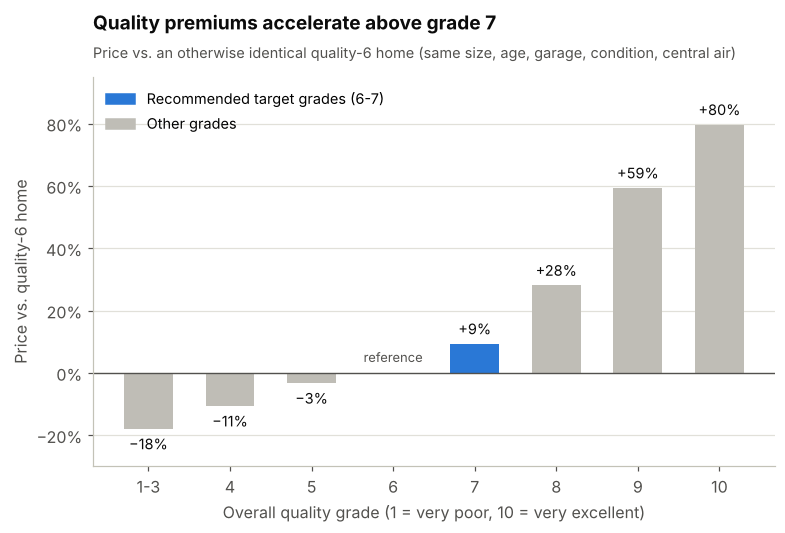

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.6))
x = np.arange(len(grades))
ax.bar(x, premium.to_numpy(), width=0.6, color=[BLUE if g in ("6", "7") else CONTEXT_GREY for g in grades])
ax.axhline(0, color=INK_2, linewidth=0.9)
for xi, (grade, value) in zip(x, premium.items()):
    if grade == "6":
        ax.text(xi, 0.025, "reference", ha="center", va="bottom", fontsize=8.5, color=INK_2)
    elif value > 0:
        ax.text(xi, value + 0.02, pct(value), ha="center", va="bottom", fontsize=9.5, color=INK)
    else:
        ax.text(xi, value - 0.02, pct(value), ha="center", va="top", fontsize=9.5, color=INK)
ax.set_xticks(x)
ax.set_xticklabels(grades)
ax.set_xlabel("Overall quality grade (1 = very poor, 10 = very excellent)")
ax.set_ylabel("Price vs. quality-6 home")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(-0.3, 0.95)
ax.legend(handles=[Patch(color=BLUE, label="Recommended target grades (6-7)"),
                   Patch(color=CONTEXT_GREY, label="Other grades")], loc="upper left")
add_titles(ax, "Quality premiums accelerate above grade 7",
           "Price vs. an otherwise identical quality-6 home (same size, age, garage, condition, central air)")
save_fig(fig, "quality_premium")
plt.show()

The model explains 86% of the variation in log price. Holding everything else equal, moving from grade 5 to grade 6 costs only about 3.5%, and from 6 to 7 about 9%, but the next steps cost 17% (7→8) and 24% (8→9). For a buyer, grades 6–7 are where better construction is cheapest to buy. Among the other attributes, central air (+11%), each garage space (+8%) and each point of condition (+6%) carry meaningful premiums. Condition matters once age is held constant, even though its raw correlation with price was slightly negative.

### 7.1 What the two anomalies did to the model

In [24]:
def model_summary(m):
    c = m["coefs"]["coef"]
    return pd.Series({"Homes": m["n"], "R-squared": round(m["r2"], 3),
                      "Living-area elasticity": round(c["LogLivArea"], 3),
                      "Quality-10 premium vs. quality 6": f"{np.exp(c['Qual_10']) - 1:+.1%}",
                      "Effect of +1 garage space": f"{np.exp(c['GarageCars']) - 1:+.1%}"})


display(pd.DataFrame({f"All {len(df):,} sales": model_summary(model_all),
                      f"Without the {anomaly.sum()} anomalies": model_summary(model)}))

,"All 1,460 sales",Without the 2 anomalies
Homes,1460,1458
R-squared,0.843,0.856
Living-area elasticity,0.487,0.508
Quality-10 premium vs. quality 6,+56.8%,+79.6%
Effect of +1 garage space,+8.6%,+8.0%


Two sales out of 1,460 are enough to cut the estimated premium for quality-10 homes from about +80% to +57% and to lower the model's fit. Excluding them is what keeps the value estimates for large, top-quality homes from being dragged down.

### 7.2 Sensitivity check: the incomplete columns

In [25]:
sens = clean.assign(LogLotArea=np.log(clean["LotArea"]))
rows = []
for extra, label in [("TotalBsmtSF", "Basement area (effect per 100 sq ft)"),
                     ("LogLotArea", "Lot area (effect of a 10% larger lot)")]:
    sub = sens.dropna(subset=[extra])
    base = fit_ols(sub, "LogPrice", PREDICTORS)
    plus = fit_ols(sub, "LogPrice", PREDICTORS + [extra])
    coef = plus["coefs"].loc[extra, "coef"]
    effect = np.exp(100 * coef) - 1 if extra == "TotalBsmtSF" else 1.10 ** coef - 1
    rows.append({
        "Added variable": label,
        "Homes with it recorded": sub.shape[0],
        "R-squared without / with": f"{base['r2']:.3f} / {plus['r2']:.3f}",
        "Its effect on price": f"{effect:+.1%}",
        "Quality-8 premium without / with": f"{np.exp(base['coefs'].loc['Qual_8', 'coef']) - 1:+.0%} / "
                                            f"{np.exp(plus['coefs'].loc['Qual_8', 'coef']) - 1:+.0%}",
        "Living-area elasticity without / with": f"{base['coefs'].loc['LogLivArea', 'coef']:.2f} / "
                                                 f"{plus['coefs'].loc['LogLivArea', 'coef']:.2f}",
    })
display(pd.DataFrame(rows).set_index("Added variable").T)

Added variable,Basement area (effect per 100 sq ft),Lot area (effect of a 10% larger lot)
Homes with it recorded,913,1339
R-squared without / with,0.848 / 0.869,0.856 / 0.879
Its effect on price,+1.8%,+1.2%
Quality-8 premium without / with,+29% / +22%,+28% / +29%
Living-area elasticity without / with,0.51 / 0.49,0.51 / 0.44


Adding basement or lot area (on the homes where they are recorded) improves the fit modestly and shifts some of the credit away from quality and living area, but every effect keeps its direction and the quality ladder keeps its shape. The conclusions do not depend on leaving these columns out.

### 7.3 How accurate are the value estimates?

In [26]:
df["EstValue"] = np.exp(predict_log_price(model, df))
df["PriceToValue"] = df["SalePrice"] / df["EstValue"]
clean = df[~anomaly].copy()
in_sample_err = (clean["PriceToValue"] - 1).abs()

# 5-fold cross-validation: each home's value is estimated by a model that never saw that home.
rng = np.random.default_rng(607)
folds = np.array_split(rng.permutation(clean.index.to_numpy()), 5)
cv_parts = []
for test_idx in folds:
    m = fit_ols(clean.drop(index=test_idx), "LogPrice", PREDICTORS)
    est = np.exp(predict_log_price(m, clean.loc[test_idx]))
    cv_parts.append((clean.loc[test_idx, "SalePrice"] / est - 1).abs())
cv_err = pd.concat(cv_parts)

accuracy = pd.DataFrame({
    "In-sample": [in_sample_err.median(), (in_sample_err <= 0.10).mean(), (in_sample_err <= 0.20).mean()],
    "5-fold cross-validated": [cv_err.median(), (cv_err <= 0.10).mean(), (cv_err <= 0.20).mean()],
}, index=["Median absolute error (%)", "Share of homes within 10% (%)", "Share of homes within 20% (%)"])
display((accuracy * 100).round(1))

,In-sample,5-fold cross-validated
Median absolute error (%),8.9,9.0
Share of homes within 10% (%),55.1,54.9
Share of homes within 20% (%),84.8,85.0


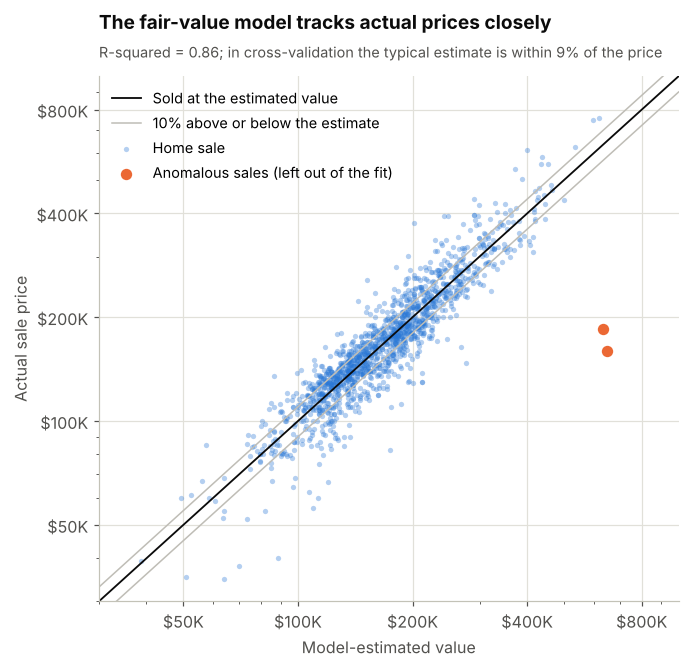

In [27]:
fig, ax = plt.subplots(figsize=(6.8, 6.2))
ax.grid(True, axis="both")
lims = np.array([30_000, 1_000_000])
ax.plot(lims, lims, color=INK, linewidth=1.2, label="Sold at the estimated value")
ax.plot(lims, lims * 1.1, color=CONTEXT_GREY, linewidth=1, label="10% above or below the estimate")
ax.plot(lims, lims * 0.9, color=CONTEXT_GREY, linewidth=1)
ax.scatter(clean["EstValue"], clean["SalePrice"], s=12, color=BLUE, alpha=0.35, linewidths=0, label="Home sale")
ax.scatter(df.loc[anomaly, "EstValue"], df.loc[anomaly, "SalePrice"], s=80, color=ORANGE, edgecolors="white",
           linewidths=1.5, zorder=4, label="Anomalous sales (left out of the fit)")
ax.set_xscale("log")
ax.set_yscale("log")
ticks = [50_000, 100_000, 200_000, 400_000, 800_000]
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FuncFormatter(k_fmt))
    axis.set_minor_formatter(NullFormatter())
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xlim(*lims)
ax.set_ylim(*lims)
ax.set_xlabel("Model-estimated value")
ax.set_ylabel("Actual sale price")
ax.legend(loc="upper left")
add_titles(ax, "The fair-value model tracks actual prices closely",
           f"R-squared = {model['r2']:.2f}; in cross-validation the typical estimate is within {cv_err.median():.0%} of the price")
save_fig(fig, "actual_vs_estimated")
plt.show()

Half of the estimates fall within about 9% of the actual price, and the cross-validated error matches the in-sample error, so the model is not overfitted. A ±9% typical error is good enough to tell whether an asking price is in the right range, not precise enough to price a specific house to the dollar. The anomalous sales sit far below the diagonal: the model values them at several times their recorded prices.

## 8. Turning the analysis into buying advice

### 8.1 Three ways to approach the ABC market

I compare three strategies a buyer could follow, defined by quality grade: an **entry** home (grades 1–5), a **mid-quality** home (grades 6–7) or a **high-quality** home (grades 8–10).

In [28]:
def share(v):
    """Percentage for a share; never rounds a share just below 100% up to '100%'."""
    return ">99%" if 0.995 <= v < 1 else f"{v:.0%}"


tier_names = ["A. Entry (quality 1-5)", "B. Mid-quality (6-7)", "C. High-quality (8-10)"]
df["Tier"] = pd.cut(df["OverallQual"], bins=[0, 5, 7, 10], labels=tier_names)
clean = df[~anomaly].copy()
g = df.groupby("Tier", observed=True)
err_by_tier = (clean["PriceToValue"] - 1).abs().groupby(clean["Tier"], observed=True)

tiers = pd.DataFrame({
    "Homes sold": g.size().map(lambda v: f"{v:,}"),
    "Share of all sales": (g.size() / len(df)).map(lambda v: f"{v:.0%}"),
    "Median price": g["SalePrice"].median().map(usd),
    "Middle 50% of prices": g["SalePrice"].quantile(0.25).map(usd) + " - " + g["SalePrice"].quantile(0.75).map(usd),
    "Median living area (sq ft)": g["LivArea"].median().map(lambda v: f"{v:,.0f}"),
    "Median price per sq ft": g["PricePerSqFt"].median().map(usd),
    "Median year built": g["YearBuilt"].median().map(lambda v: f"{v:.0f}"),
    "Central air": g["CentralAirY"].mean().map(share),
    "Garage for 2+ cars": g["GarageCars"].apply(lambda s: (s >= 2).mean()).map(share),
    "Typical valuation error (median abs. %)": err_by_tier.median().map(lambda v: f"{v:.1%}"),
})
display(tiers.T)

Tier,A. Entry (quality 1-5),B. Mid-quality (6-7),C. High-quality (8-10)
Homes sold,538,693,229
Share of all sales,37%,47%,16%
Median price,"$127,750","$178,900","$285,000"
Middle 50% of prices,"$108,000 - $143,000","$151,000 - $208,900","$245,350 - $342,643"
Median living area (sq ft),"1,120","1,512","1,915"
Median price per sq ft,$111,$119,$151
Median year built,1957,1984,2004
Central air,87%,97%,>99%
Garage for 2+ cars,41%,82%,99%
Typical valuation error (median abs. %),9.0%,8.3%,9.8%


- **Entry homes** are cheapest per square foot but are small and old (median 1957), 13% lack central air and most have a one-car garage or none, so upgrade costs come on top of the price.
- **High-quality homes** cost 27% more per square foot than mid-quality homes, make up only 16% of sales, and their values are the hardest to pin down — a thin market in which it is easier to overpay and harder to resell.
- **Mid-quality homes** are nearly half of all sales (the deepest pool of comparable sales and future buyers) and cost only about 7% more per square foot than entry homes, yet 97% have central air and 82% a garage for two or more cars. Their prices are also the most predictable.

### 8.2 The recommended screen and the value test

In [29]:
screen = df["OverallQual"].between(6, 7) & (df["CentralAirY"] == 1) & (df["GarageCars"] >= 2) & ~anomaly
target = df[screen]
below = target["PriceToValue"] <= 0.90
above = target["PriceToValue"] >= 1.10
print(f"Homes matching the screen (quality 6-7, central air, 2+ car garage): {screen.sum():,} "
      f"({screen.mean():.0%} of all sales)")
print(f"Median price {usd(target['SalePrice'].median())}; middle 50%: "
      f"{usd(target['SalePrice'].quantile(0.25))} - {usd(target['SalePrice'].quantile(0.75))}")
print(f"Median living area {target['LivArea'].median():,.0f} sq ft; median price per sq ft "
      f"{usd(target['PricePerSqFt'].median(), 2)}; median year built {target['YearBuilt'].median():.0f}")
print(f"Sold 10%+ BELOW estimated value: {below.sum()} homes ({below.mean():.0%}); median saving "
      f"{usd((target.loc[below, 'EstValue'] - target.loc[below, 'SalePrice']).median())}")
print(f"Sold 10%+ ABOVE estimated value: {above.sum()} homes ({above.mean():.0%}); median overpayment "
      f"{usd((target.loc[above, 'SalePrice'] - target.loc[above, 'EstValue']).median())}")

market = df[~anomaly]
m_below, m_above = market["PriceToValue"] <= 0.90, market["PriceToValue"] >= 1.10
print(f"\nWhole market: {m_above.mean():.0%} of sales closed 10%+ above estimated value (median overpayment "
      f"{usd((market.loc[m_above, 'SalePrice'] - market.loc[m_above, 'EstValue']).median())}); "
      f"{m_below.mean():.0%} closed 10%+ below (median saving "
      f"{usd((market.loc[m_below, 'EstValue'] - market.loc[m_below, 'SalePrice']).median())}).")

Homes matching the screen (quality 6-7, central air, 2+ car garage): 554 (38% of all sales)
Median price $185,800; middle 50%: $165,000 - $215,000
Median living area 1,556 sq ft; median price per sq ft $121.58; median year built 1995
Sold 10%+ BELOW estimated value: 104 homes (19%); median saving $26,648
Sold 10%+ ABOVE estimated value: 115 homes (21%); median overpayment $31,858

Whole market: 24% of sales closed 10%+ above estimated value (median overpayment $27,665); 21% closed 10%+ below (median saving $27,653).


Within the recommended segment, roughly one sale in five closed at least 10% below the model's estimate and another one in five at least 10% above it. On a typical home, the difference between those two outcomes is tens of thousands of dollars, which is why the estimate should anchor every offer. The deepest "discounts" deserve suspicion rather than celebration: this subset of the data has no field for sale condition or building type, so some may be foreclosures, family transfers, townhouses, or homes needing major repairs.

In [30]:
examples = target.loc[below].nsmallest(8, "PriceToValue")[
    ["Id", "SalePrice", "EstValue", "PriceToValue", "OverallQual", "OverallCond", "YearBuilt", "LivArea", "YrSold"]]
display(examples.round({"EstValue": 0, "PriceToValue": 2}))

,Id,SalePrice,EstValue,PriceToValue,OverallQual,OverallCond,YearBuilt,LivArea,YrSold
632,633,82500,174919.0,0.47,7,5,1977,1411,2009
1216,1217,112000,186938.0,0.60,6,5,1978,1902,2010
193,194,130000,212068.0,0.61,7,5,2004,1709,2006
1304,1305,130000,212005.0,0.61,7,5,2004,1708,2006
666,667,129000,200112.0,0.64,6,5,1965,2380,2007
1088,1089,137500,212068.0,0.65,7,5,2004,1709,2006
714,715,130500,195392.0,0.67,6,8,1976,1479,2010
145,146,130000,194042.0,0.67,6,5,2004,1709,2006


## 9. Summary

| Question | Answer |
|---|---|
| **Q1. Mean and standard deviation** | Mean **\$180,921.20**; standard deviation **\$79,442.50** (sample). Median \$163,000; middle half \$129,975–\$214,000. |
| **Q2. Histogram** | Single-peaked and right-skewed (skewness 1.88): most sales fall between \$100,000 and \$250,000, with a long tail to \$755,000. Log prices are nearly symmetric. |
| **Q3. Outliers and handling** | 61 high-price outliers above \$340,037.50 (Tukey's fences): genuine luxury homes, kept, with medians reported and log price modeled. Two anomalous sales (Ids 524, 1299; 4,676–5,642 sq ft sold for \$28–\$40 per sq ft) excluded from the model. Missing basement, frontage and lot data handled by leaving those columns out of the main model and checking sensitivity. |

**Recommendations for the clients** (developed in the report):

1. Budget around the median (\$163,000) and the middle half of the market, not the \$180,921 mean.
2. Target quality-6 or quality-7 homes with central air and a two-car garage: the cheapest quality upgrades, the deepest resale market and the most predictable prices.
3. Check every asking price against the fair-value estimate; treat asking prices more than 10% above it as negotiable unless the home has features the model cannot see, such as a finished basement or a larger lot.
4. Investigate unusually cheap large or high-quality homes before bidding: the data cannot rule out partial, distressed or non-market sales.